# SHL Hiring Assessment 2026: Grammar Scoring from Speech

The task is to predict a grammar score from 0 to 5 for each spoken English clip. There are 769 training clips and 216 test clips, and the metric is RMSE.

## Summary

**Approach.**
- Every clip is described by several frozen pretrained models:
  - speech encoders;
  - the Whisper decoder run over the transcript;
  - two audio LLMs;
  - two text LLMs reading ASR transcripts with the competition rubric;
  - a table of interpretable fluency and grammar features.
- A small regressor (Ridge, SVR or LightGBM) is fitted on each representation.
- Their out-of-fold predictions are combined with non-negative least squares.

**Findings that shaped the solution.**
1. **Speaker leakage.** Training candidates contributed about three responses each, with near-identical grades. Test speakers never appear in training. All validation therefore uses folds grouped by speaker. Random K-fold overestimates the audio models badly.
2. **Grade-0 batch.** The 37 clips graded 0 are a separate recording batch. A loudness statistic separates them perfectly.
3. **The 45-second batch.** Almost half of the test set comes from a ~45 s recording batch that is rare in training, so the stacker learns separate weights for it.

**Results.**

| | RMSE |
|---|---|
| Speaker-grouped CV, nested stack | 0.509 |
| Training (in-sample) | 0.225 |
| Public leaderboard | 0.3382 |

**Layout.** `extract_features.py` produces every feature and writes it to `features/`. It covers speech recognition, the audio and text models, and the interpretable features. It ran on Kaggle (2× T4, about 8 GPU-hours).

This notebook does the modelling from `features/`. It runs on a CPU in about a minute.

In [1]:
import json
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy.optimize import nnls
from scipy.sparse.csgraph import connected_components
from scipy.stats import pearsonr
from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

DATA = Path('data')            # competition train.csv and test.csv
FEAT = Path('features')        # written by extract_features.py

train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
N_TRAIN = len(train)
KEYS = [f'train/{f}' for f in train.filename] + [f'test/{f}' for f in test.filename]   # filenames repeat across splits
y_all = train.label.to_numpy(float)


def rmse(a, b):
    return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))


def reorder(keys):
    pos = {k: i for i, k in enumerate(keys)}
    return np.array([pos[k] for k in KEYS])

## 1. Data

Most training clips are 60 s long. Durations also reveal a separate batch of clips that are exactly ~45.06 s long. That batch is 14% of training but 47% of test, and its grades are lower on average.

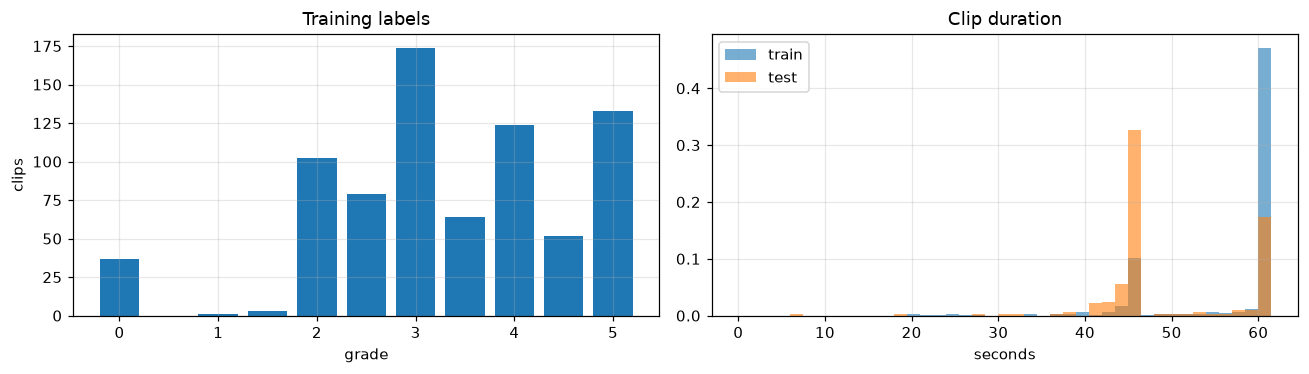

,train share,test share,"mean grade (train, >0)"
45 s,0.135,0.468,2.922
60 s,0.714,0.269,3.582
< 44 s,0.060,0.111,3.367
44-59 s,0.091,0.153,3.636


In [2]:
duration = pd.read_csv(FEAT / 'asr/audio_stats.csv').duration.to_numpy()


def batch(d):
    return np.where(np.abs(d - 45.06) < 0.1, 0, np.where(d > 59.5, 1, np.where(d < 44, 2, 3)))


BATCH = batch(duration)
BATCH_NAMES = ['45 s', '60 s', '< 44 s', '44-59 s']

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
counts = train.label.value_counts().sort_index()
ax[0].bar(counts.index, counts.values, width=0.4)
ax[0].set(title='Training labels', xlabel='grade', ylabel='clips')
bins = np.arange(0, 63, 1.5)
ax[1].hist(duration[:N_TRAIN], bins, density=True, alpha=0.6, label='train')
ax[1].hist(duration[N_TRAIN:], bins, density=True, alpha=0.6, label='test')
ax[1].set(title='Clip duration', xlabel='seconds')
ax[1].legend()
plt.tight_layout()
plt.show()

pd.DataFrame({
    'train share': np.bincount(BATCH[:N_TRAIN], minlength=4) / N_TRAIN,
    'test share': np.bincount(BATCH[N_TRAIN:], minlength=4) / len(test),
    'mean grade (train, >0)': [y_all[(BATCH[:N_TRAIN] == b) & (y_all > 0)].mean() for b in range(4)],
}, index=BATCH_NAMES).round(3)

## 2. Grade-0 clips

The rubric covers grades 1–5. The 37 clips graded 0 (`audio_5037`–`audio_5073`) are loud from start to finish.

The *speech ratio* is the share of 25 ms frames with RMS above 0.02. It reaches 0.99 only for these clips. The models are therefore trained on graded clips only, and any test clip above that threshold is set to 0. Only `audio_134.wav` qualifies; the next-highest test value is 0.84.

train zeros caught: 37 of 37 | false positives: 0 | gated test clips: ['audio_134.wav']


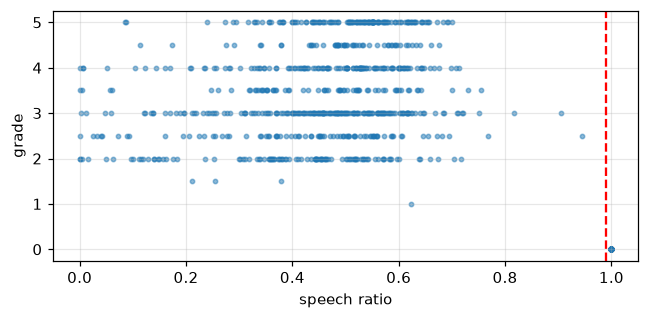

In [3]:
speech_ratio = np.load(FEAT / 'audio/speech_ratio.npy')
gate = speech_ratio >= 0.99
print('train zeros caught:', (gate[:N_TRAIN] & (y_all == 0)).sum(), 'of', (y_all == 0).sum(),
      '| false positives:', (gate[:N_TRAIN] & (y_all > 0)).sum(),
      '| gated test clips:', list(test.filename[gate[N_TRAIN:]]))

plt.figure(figsize=(6, 3))
plt.scatter(speech_ratio[:N_TRAIN], y_all, s=8, alpha=0.5)
plt.axvline(0.99, color='r', ls='--')
plt.xlabel('speech ratio')
plt.ylabel('grade')
plt.tight_layout()
plt.show()

nz = np.flatnonzero(y_all > 0)
y = y_all[nz]
B_TR, B_TE = BATCH[:N_TRAIN][nz], BATCH[N_TRAIN:]

## 3. Speaker groups and validation

Early WavLM layers mostly encode who is speaking. We compare clips by cosine similarity of these voice features:
- nearly every training clip has a near-identical voice elsewhere in training, usually the neighbouring file number;
- no test clip does.

We link training clips whose similarity exceeds the 99.5th percentile of the test→train similarities. Because test speakers are unseen, that distribution describes different speakers. The connected components are taken as speaker groups.

420 groups, sizes 1/2/3: 227/76/114; grade std within a group 0.16 vs 1.01 overall


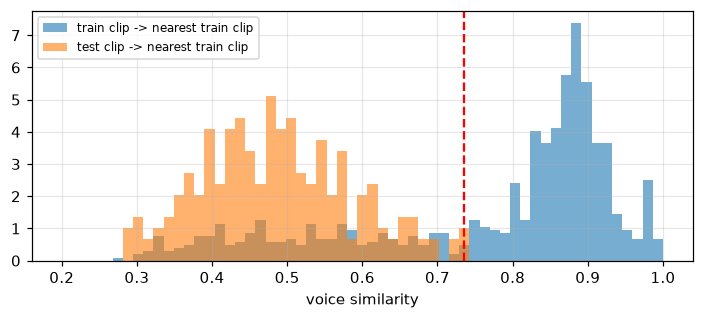

In [4]:
wavlm_mean = np.load(FEAT / 'speech/wavlm_mean.npy').astype(np.float32)
wavlm_std = np.load(FEAT / 'speech/wavlm_std.npy').astype(np.float32)
voice = np.hstack([wavlm_mean[:, 3], wavlm_std[:, 3], wavlm_mean[:, 6], wavlm_std[:, 6]])
voice = (voice - voice.mean(0)) / (voice.std(0) + 1e-6)
voice /= np.linalg.norm(voice, axis=1, keepdims=True)
sim = voice @ voice.T
np.fill_diagonal(sim, -1)

nn_train = sim[:N_TRAIN, :N_TRAIN].max(1)
nn_test = sim[N_TRAIN:, :N_TRAIN].max(1)
tau = np.percentile(nn_test, 99.5)
n_groups, groups = connected_components(sim[:N_TRAIN, :N_TRAIN] > tau, directed=False)
sizes = np.bincount(groups)
multi = [g for g in range(n_groups) if 1 < sizes[g] < 10]
print(f'{n_groups} groups, sizes 1/2/3: {(sizes == 1).sum()}/{(sizes == 2).sum()}/{(sizes == 3).sum()}; '
      f'grade std within a group {np.mean([y_all[groups == g].std() for g in multi]):.2f} vs {y.std():.2f} overall')

plt.figure(figsize=(6.5, 3))
edges = np.linspace(0.2, 1, 60)
plt.hist(nn_train, edges, alpha=0.6, density=True, label='train clip -> nearest train clip')
plt.hist(nn_test, edges, alpha=0.6, density=True, label='test clip -> nearest train clip')
plt.axvline(tau, color='r', ls='--')
plt.xlabel('voice similarity')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

All models are evaluated with `StratifiedGroupKFold` over these groups: 5 folds, repeated 3 times. With random folds, the same audio model looks about 0.08 RMSE better, because the speaker's other answers are in the training fold.

In [5]:
def grade_bins(v):
    b = np.round(v * 2).astype(int)
    b[b < 4] = 4
    return b


FOLDS = [list(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(nz, grade_bins(y), groups[nz])) for s in range(3)]
RANDOM_FOLDS = [list(StratifiedKFold(5, shuffle=True, random_state=s).split(nz, grade_bins(y))) for s in range(3)]


def cross_val(model, X, folds=FOLDS, refit=False):
    """Out-of-fold predictions (3 repeats x graded clips) and test predictions.
    Test predictions are the mean of the 15 fold models, or a refit on all graded clips if refit=True."""
    X_tr, X_te = X[:N_TRAIN][nz], X[N_TRAIN:]

    def fit(r, tr, va):
        m = clone(model).fit(X_tr[tr], y[tr])
        return r, va, m.predict(X_tr[va]), m.predict(X_te)

    oof, pred = np.zeros((len(folds), len(y))), np.zeros(len(X_te))
    runs = Parallel(n_jobs=-1)(delayed(fit)(r, tr, va) for r, fold in enumerate(folds) for tr, va in fold)
    for r, va, p, t in runs:
        oof[r, va] = p
        pred += t / len(runs)
    if refit:
        pred = clone(model).fit(X_tr, y).predict(X_te)
    return np.clip(oof, 1, 5), np.clip(pred, 1, 5)


def score(oof):
    return float(np.mean([rmse(o, y) for o in oof]))


whisper_enc = np.load(FEAT / 'speech/whisperenc_mean.npy').astype(np.float32)
demo = make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.1))
print('Whisper encoder layer 22 + SVR')
print(f'  random folds : {score(cross_val(demo, whisper_enc[:, 22], RANDOM_FOLDS)[0]):.3f}')
print(f'  speaker folds: {score(cross_val(demo, whisper_enc[:, 22])[0]):.3f}')

Whisper encoder layer 22 + SVR


  random folds : 0.522


  speaker folds: 0.600


## 4. Representations

The layer choices below come from grouped-CV sweeps.

| source | input to the regressor |
|---|---|
| Whisper encoder / WavLM | mean over frames, layers 30–32 / 19–21 |
| Whisper decoder | mean over tokens: verbatim transcript, layers 20–22; Parakeet transcript, layers 7–9 and 9 |
| Qwen2-Audio / Voxtral | audio-token mean (and Qwen2-Audio's last token) at layer 14, and Voxtral layers 9–14 |
| Qwen2.5-7B / 14B | transcript-token mean and last token at mid-depth layers |
| hand-crafted | the interpretable-feature table from `extract_features.py`, plus all LLM score-digit probabilities and expected scores |

In [6]:
def mean_of_layers(E, layers):
    return E[:, layers].mean(1)


def llm_hidden(tag, variant, kind):
    E = np.load(FEAT / f'text_llm/{tag}__{variant}__grammar__{kind}.npy').astype(np.float32)
    return E[reorder(json.load(open(FEAT / f'text_llm/keys_{variant}.json')))]


def llm_probs(tag, variants):
    blocks = []
    for v in variants:
        order = reorder(json.load(open(FEAT / f'text_llm/keys_{v}.json')))
        for prompt in ['grammar', 'vocab', 'coherence', 'cefr', 'errors']:
            P = np.load(FEAT / f'text_llm/{tag}__{v}__{prompt}__probs.npy')[order]
            k = P.shape[1] - 1                                   # last column is the probability mass on digits
            blocks.append(np.hstack([P[:, :k], (P[:, :k] * np.arange(1, k + 1)).sum(1, keepdims=True)]))
    return np.hstack(blocks)


qa_order = reorder(json.load(open(FEAT / 'audio_llm/qaudio_meta.json'))['keys'])
qaudio_audio = np.load(FEAT / 'audio_llm/qaudio_audiomean.npy').astype(np.float32)[qa_order]
qaudio_last = np.load(FEAT / 'audio_llm/qaudio_last.npy').astype(np.float32)[qa_order]
vox = np.load(FEAT / 'audio_llm/vox_amean.npy').astype(np.float32)
wdec = np.load(FEAT / 'decoder/wdec_verbatim_mean.npy').astype(np.float32)
wdec_pk = np.load(FEAT / 'decoder/wdec_parakeet_mean.npy').astype(np.float32)
q7_verbatim = llm_hidden('Qwen2.5-7B-Instruct', 'verbatim', 'mean')
q7_plain_last = llm_hidden('Qwen2.5-7B-Instruct', 'plain', 'last')
q14_mean = llm_hidden('Qwen2.5-14B-Instruct', 'parakeet', 'mean')
q14_last = llm_hidden('Qwen2.5-14B-Instruct', 'parakeet', 'last')
hand = pd.read_csv(FEAT / 'hand_features.csv').set_index('key')
probs = np.hstack([llm_probs('Qwen2.5-7B-Instruct', ['verbatim', 'plain']),
                   llm_probs('Qwen2.5-14B-Instruct', ['wv2', 'parakeet'])])

X = {
    'whisper_enc': mean_of_layers(whisper_enc, [30, 31, 32]),
    'wavlm': mean_of_layers(wavlm_mean, [19, 20, 21]),
    'whisper_dec': mean_of_layers(wdec, [20, 21, 22]),
    'whisper_dec_pk': mean_of_layers(wdec_pk, [7, 8, 9]),
    'whisper_dec_pk_L9': wdec_pk[:, 9],
    'qwen2audio_audio': qaudio_audio[:, 1],
    'qwen2audio_last': qaudio_last[:, 1],
    'voxtral': mean_of_layers(vox, [0, 1]),
    'voxtral_L14': vox[:, 1],
    'qwen7b_L17': q7_verbatim[:, 3],
    'qwen7b_L21': q7_verbatim[:, 4],
    'qwen7b_last': q7_plain_last[:, 3],
    'qwen14b_mean': mean_of_layers(q14_mean, [3, 6]),
    'qwen14b_last': q14_last[:, 2],
    'hand': np.hstack([hand.loc[KEYS].values, probs]),
}
pd.DataFrame({'dimensions': {k: v.shape[1] for k, v in X.items()}})

,dimensions
whisper_enc,1280
wavlm,1024
whisper_dec,1280
whisper_dec_pk,1280
whisper_dec_pk_L9,1280
qwen2audio_audio,4096
qwen2audio_last,4096
voxtral,3072
voxtral_L14,3072
qwen7b_L17,3584


The interpretable features most correlated with the grade:
- Whisper's word confidence;
- lexical diversity;
- the rate of grammatical corrections the LLM had to make (negative);
- the disagreement between ASR systems (negative).

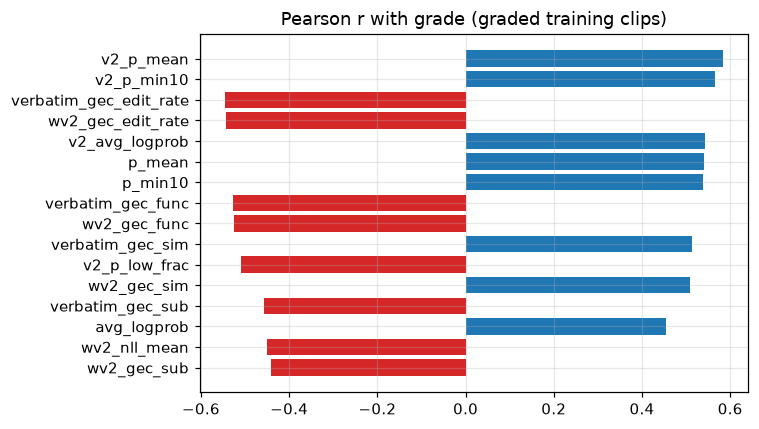

In [7]:
corr = hand.loc[KEYS].iloc[:N_TRAIN].iloc[nz].apply(lambda c: np.corrcoef(c, y)[0, 1] if c.std() > 0 else 0)
top = corr.reindex(corr.abs().sort_values().index[-16:])
plt.figure(figsize=(7, 4))
plt.barh(top.index, top.values, color=np.where(top.values < 0, 'C3', 'C0'))
plt.title('Pearson r with grade (graded training clips)')
plt.tight_layout()
plt.show()

## 5. Base models

Each representation gets:
- a Ridge (alpha scaled by the feature dimension); or
- an RBF-SVR on standardised features; or
- LightGBM, for the tabular set.

Test predictions average the 15 fold models. The two tabular models are instead refitted once on all graded clips.

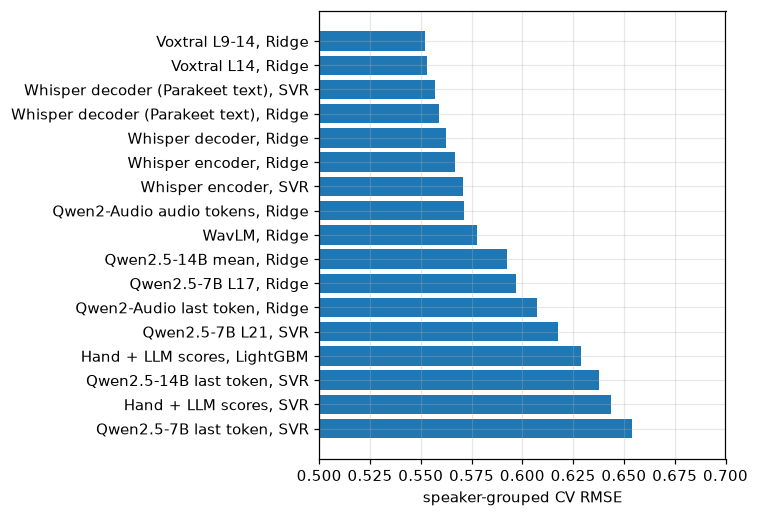

,CV RMSE,Pearson
"Voxtral L9-14, Ridge",0.5519,0.8405
"Voxtral L14, Ridge",0.5530,0.8401
"Whisper decoder (Parakeet text), SVR",0.5568,0.8378
"Whisper decoder (Parakeet text), Ridge",0.5591,0.8345
"Whisper decoder, Ridge",0.5624,0.8323
"Whisper encoder, Ridge",0.5668,0.8299
"Whisper encoder, SVR",0.5708,0.8281
"Qwen2-Audio audio tokens, Ridge",0.5714,0.8261
"WavLM, Ridge",0.5777,0.8229
"Qwen2.5-14B mean, Ridge",0.5923,0.8129


In [8]:
def ridge(alpha, d):
    return make_pipeline(StandardScaler(), Ridge(alpha=alpha * d))


def svr(C, d):
    return make_pipeline(StandardScaler(), SVR(C=C, gamma=1.0 / d, epsilon=0.1))


d = {k: v.shape[1] for k, v in X.items()}
MODELS = {
    'Whisper encoder, Ridge': ('whisper_enc', ridge(1.0, d['whisper_enc'])),
    'Whisper encoder, SVR': ('whisper_enc', svr(3, d['whisper_enc'])),
    'WavLM, Ridge': ('wavlm', ridge(1.0, d['wavlm'])),
    'Whisper decoder, Ridge': ('whisper_dec', ridge(1.0, d['whisper_dec'])),
    'Whisper decoder (Parakeet text), SVR': ('whisper_dec_pk_L9', svr(3, d['whisper_dec_pk_L9'])),
    'Whisper decoder (Parakeet text), Ridge': ('whisper_dec_pk', ridge(1.0, d['whisper_dec_pk'])),
    'Qwen2-Audio audio tokens, Ridge': ('qwen2audio_audio', ridge(0.3, d['qwen2audio_audio'])),
    'Qwen2-Audio last token, Ridge': ('qwen2audio_last', ridge(1.0, d['qwen2audio_last'])),
    'Qwen2.5-7B L17, Ridge': ('qwen7b_L17', ridge(1.0, d['qwen7b_L17'])),
    'Qwen2.5-7B L21, SVR': ('qwen7b_L21', svr(1, d['qwen7b_L21'])),
    'Qwen2.5-7B last token, SVR': ('qwen7b_last', svr(3, d['qwen7b_last'])),
    'Qwen2.5-14B mean, Ridge': ('qwen14b_mean', ridge(1.0, d['qwen14b_mean'])),
    'Qwen2.5-14B last token, SVR': ('qwen14b_last', svr(3, d['qwen14b_last'])),
    'Hand + LLM scores, LightGBM': ('hand', lgb.LGBMRegressor(n_estimators=600, learning_rate=0.02, num_leaves=15,
                                                               min_child_samples=15, subsample=0.8, subsample_freq=1,
                                                               colsample_bytree=0.5, reg_lambda=1.0, verbose=-1,
                                                               random_state=0)),
    'Hand + LLM scores, SVR': ('hand', make_pipeline(StandardScaler(), SVR(C=1))),
    'Voxtral L9-14, Ridge': ('voxtral', ridge(1.0, d['voxtral'])),
    'Voxtral L14, Ridge': ('voxtral_L14', ridge(1.0, d['voxtral_L14'])),
}

OOF, TEST = {}, {}
for name, (src, model) in MODELS.items():
    OOF[name], TEST[name] = cross_val(model, X[src], refit=(src == 'hand'))

results = pd.DataFrame({
    'CV RMSE': {n: score(o) for n, o in OOF.items()},
    'Pearson': {n: np.mean([pearsonr(r, y)[0] for r in o]) for n, o in OOF.items()},
}).sort_values('CV RMSE')

plt.figure(figsize=(7, 4.8))
plt.barh(results.index[::-1], results['CV RMSE'][::-1])
plt.xlim(0.5, 0.7)
plt.xlabel('speaker-grouped CV RMSE')
plt.tight_layout()
plt.show()
results.round(4)

## 6. Stacking

The stacker is non-negative least squares with an intercept. It is fitted twice: once on the 45 s batch and once on all other clips. Predictions are then clipped to [2, 5], since grades below 2 make up under 1% of graded clips. Finally the zero gate is applied.

To get an honest estimate, the stacker itself is cross-validated: each fold is predicted by a stacker fitted on the other folds' out-of-fold predictions.

stack CV RMSE 0.5094, Pearson 0.8646 (best single model 0.5519)


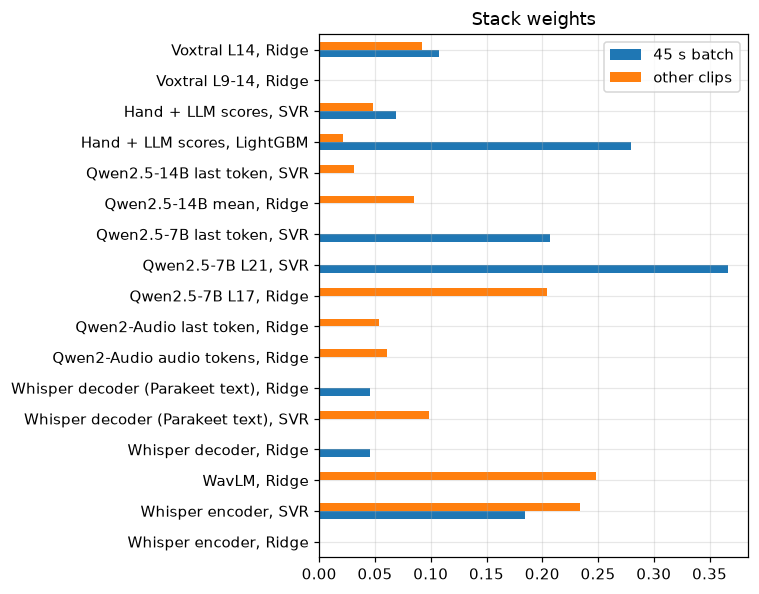

In [9]:
NAMES = list(MODELS)


def nnls_fit(P, t):
    P_mean, t_mean = P.mean(0), t.mean()
    w, _ = nnls(P - P_mean, t - t_mean)
    return w, t_mean - P_mean @ w


def stack_predict(P_fit, t_fit, b_fit, P_new, b_new):
    out = np.zeros(len(P_new))
    for is_45 in (True, False):
        fit_rows, new_rows = (b_fit == 0) == is_45, (b_new == 0) == is_45
        w, b = nnls_fit(P_fit[fit_rows], t_fit[fit_rows])
        out[new_rows] = P_new[new_rows] @ w + b
    return out


stack_oof = []
for r in range(3):
    P = np.stack([OOF[n][r] for n in NAMES], 1)
    pred = np.zeros(len(y))
    for tr, va in FOLDS[r]:
        pred[va] = stack_predict(P[tr], y[tr], B_TR[tr], P[va], B_TR[va])
    stack_oof.append(np.clip(pred, 2, 5))
stack_oof = np.array(stack_oof)
print(f'stack CV RMSE {score(stack_oof):.4f}, Pearson {np.mean([pearsonr(p, y)[0] for p in stack_oof]):.4f} '
      f'(best single model {results["CV RMSE"].min():.4f})')

P_all = np.vstack([np.stack([OOF[n][r] for n in NAMES], 1) for r in range(3)])
y_rep, b_rep = np.tile(y, 3), np.tile(B_TR, 3)
weights = pd.DataFrame({label: nnls_fit(P_all[(b_rep == 0) == is_45], y_rep[(b_rep == 0) == is_45])[0]
                        for label, is_45 in [('45 s batch', True), ('other clips', False)]}, index=NAMES)
weights.plot.barh(figsize=(7, 5.5), title='Stack weights')
plt.tight_layout()
plt.show()

On the 45 s batch, the weight moves toward the transcript and LLM models. On 60 s clips, audio representations dominate.

## 7. Evaluation

,batch,clips,RMSE,Pearson
0,45 s,103,0.487,0.797
1,60 s,518,0.514,0.865
2,< 44 s,45,0.521,0.798
3,44-59 s,66,0.444,0.906


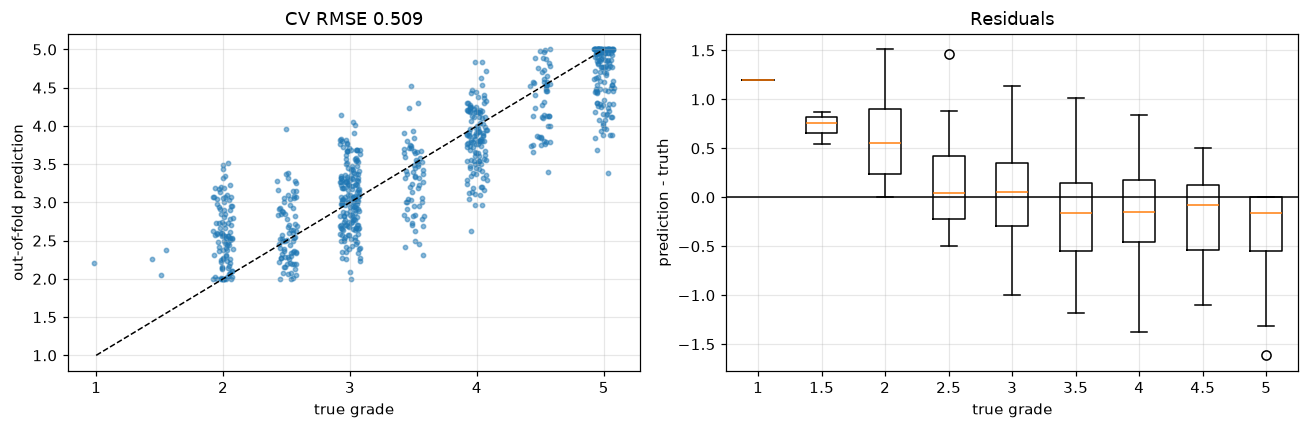

In [10]:
p = stack_oof.mean(0)
display(pd.DataFrame([{'batch': BATCH_NAMES[b], 'clips': (B_TR == b).sum(), 'RMSE': rmse(p[B_TR == b], y[B_TR == b]),
                       'Pearson': pearsonr(p[B_TR == b], y[B_TR == b])[0]} for b in range(4)]).round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
jitter = np.random.default_rng(0).uniform(-0.08, 0.08, len(y))
ax[0].scatter(y + jitter, p, s=8, alpha=0.5)
ax[0].plot([1, 5], [1, 5], 'k--', lw=1)
ax[0].set(xlabel='true grade', ylabel='out-of-fold prediction', title=f'CV RMSE {score(stack_oof):.3f}')
levels = np.unique(y)
ax[1].boxplot([p[y == v] - v for v in levels])
ax[1].set_xticks(range(1, len(levels) + 1), [f'{v:g}' for v in levels])
ax[1].axhline(0, color='k', lw=1)
ax[1].set(xlabel='true grade', ylabel='prediction - truth', title='Residuals')
plt.tight_layout()
plt.show()

**Training RMSE.** Each base model is refitted on all graded clips and scored on those same clips. The stacker weights are fitted on the out-of-fold predictions. The zero gate handles the grade-0 clips.

In [11]:
insample = []
for name in NAMES:
    src, model = MODELS[name]
    Xs = X[src][:N_TRAIN][nz]
    insample.append(np.clip(clone(model).fit(Xs, y).predict(Xs), 1, 5))
train_pred = np.zeros(N_TRAIN)
train_pred[nz] = np.clip(stack_predict(P_all, y_rep, b_rep, np.stack(insample, 1), B_TR), 2, 5)
train_pred[gate[:N_TRAIN]] = 0

cv_all = np.zeros(N_TRAIN)
cv_all[nz] = p
cv_all[gate[:N_TRAIN]] = 0

pd.DataFrame({
    'RMSE': [rmse(train_pred, y_all), rmse(train_pred[nz], y), score(stack_oof), rmse(cv_all, y_all), rmse(np.full(len(y), y.mean()), y)],
}, index=['training, all 769 clips', 'training, graded clips', 'CV, graded clips', 'CV, all clips', 'predict the mean']).round(4)

,RMSE
"training, all 769 clips",0.2247
"training, graded clips",0.2303
"CV, graded clips",0.5094
"CV, all clips",0.4924
predict the mean,1.0137


## 8. Submission

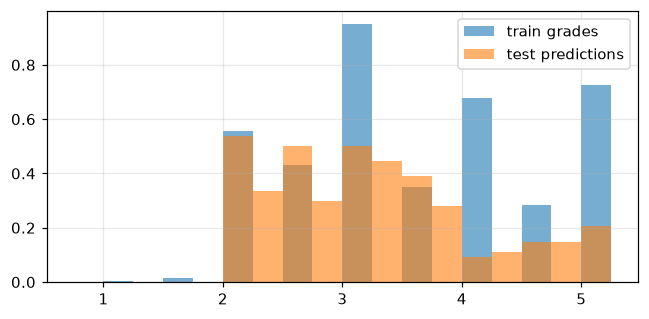

,count,mean,std,min,25%,50%,75%,max
label,216.0,3.225,0.881,0.0,2.56,3.147,3.719,5.0


In [12]:
T = np.stack([TEST[n] for n in NAMES], 1)
test_pred = np.clip(stack_predict(P_all, y_rep, b_rep, T, B_TE), 2, 5)
test_pred[gate[N_TRAIN:]] = 0

submission = pd.DataFrame({'filename': test.filename, 'label': test_pred})
submission.to_csv('submission.csv', index=False)

plt.figure(figsize=(6, 3))
plt.hist(y, np.arange(0.75, 5.5, 0.25), density=True, alpha=0.6, label='train grades')
plt.hist(test_pred[test_pred > 0], np.arange(0.75, 5.5, 0.25), density=True, alpha=0.6, label='test predictions')
plt.legend()
plt.tight_layout()
plt.show()
submission.describe().T.round(3)

## 9. Notes

- **Validation.** Moving from random to speaker-grouped folds mattered more than any single model. With random folds, the chosen stack scored 0.398 on the public leaderboard. Re-selecting under grouped folds gave 0.347, and adding more speaker-independent views (decoder, audio LLMs, text LLMs) brought it to 0.338.
- **Tried and dropped:**
  - fine-tuning DeBERTa-v3 on transcripts (0.69);
  - QLoRA on Qwen2.5-7B (0.65–0.74 per fold);
  - chunk-level training on 10 s windows;
  - isotonic or cubic calibration;
  - non-linear stackers;
  - training with the grade-0 clips;
  - importance weighting by batch;
  - pooling test predictions per speaker.
- **Limitations:**
  - Speaker groups are inferred from voice similarity.
  - ASR can quietly correct grammar errors. Several ASR views and audio-based models reduce the damage but do not remove it.
  - The grades are holistic, so fluency and pronunciation also drive them.